## SmartReview AI – Sentiment Analysis using NLP

Objective: Build a Machine Learning model using Natural Language Processing (NLP) to classify customer comments into three sentiment categories.

- 0 – Negative
- 1 – Neutral
- 2 – Positive

In [3]:
import pandas as pd
import numpy as np

In [4]:
df = pd.read_csv("sentiment_data.csv")
df

,Unnamed: 0,Comment,Sentiment
0,0,lets forget apple pay required brand new iphon...,1
1,1,nz retailers don’t even contactless credit car...,0
2,2,forever acknowledge channel help lessons ideas...,2
3,3,whenever go place doesn’t take apple pay doesn...,0
4,4,apple pay convenient secure easy use used kore...,2
...,...,...,...
241140,241921,crores paid neerav modi recovered congress lea...,0
241141,241922,dear rss terrorist payal gawar modi killing pl...,0
241142,241923,cover interaction forum left,1
241143,241924,big project came india modi dream project happ...,1


In [5]:
df.drop(columns=['Unnamed: 0'],inplace=True)
df.head()

,Comment,Sentiment
0,lets forget apple pay required brand new iphon...,1
1,nz retailers don’t even contactless credit car...,0
2,forever acknowledge channel help lessons ideas...,2
3,whenever go place doesn’t take apple pay doesn...,0
4,apple pay convenient secure easy use used kore...,2


In [6]:
df.shape

(241145, 2)

In [7]:
df.columns

Index(['Comment', 'Sentiment'], dtype='object')

In [8]:
df.isnull().sum()

Comment      217
Sentiment      0
dtype: int64

In [9]:
df = df.dropna(subset=['Comment'])
df.isnull().sum()

Comment      0
Sentiment    0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(26595)

In [11]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [12]:
df['Sentiment'].value_counts()

Sentiment
2    94251
1    71771
0    48311
Name: count, dtype: int64

In [13]:
X = df['Comment']
y = df['Sentiment']

In [14]:
print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (214333,)
Output shape: (214333,)


In [15]:
y.value_counts()

Sentiment
2    94251
1    71771
0    48311
Name: count, dtype: int64

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [17]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (171466,)
X_test: (42867,)
y_train: (171466,)
y_test: (42867,)


In [18]:
print("Training distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))

Training distribution:
Sentiment
2    0.439737
1    0.334859
0    0.225403
Name: proportion, dtype: float64

Testing distribution:
Sentiment
2    0.439756
1    0.334850
0    0.225395
Name: proportion, dtype: float64


In [19]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

In [20]:
X_train = X_train.apply(clean_text)
X_test = X_test.apply(clean_text)

In [21]:
X_train.head(10)

196870    sense bjp get atleast seats come may happen co...
95043     tum woh har vaada tod dete pakistani may bette...
189846    modi campaigning rahulrahul campaigning modi g...
147162    congress approve china modi gave goahead years...
103186    modi nothing performancewise else sayhis promises
605       empres rios entrem com a o stf j com intuito d...
159468    cnn indian prime minister narendra modi says c...
43037                      side seat loner please starbucks
102224    congress history making country crippled annou...
58538                                           youre silly
Name: Comment, dtype: object

In [22]:
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer()

In [23]:
X_train_bow = cv.fit_transform(X_train)

In [24]:
X_test_bow = cv.transform(X_test)

In [25]:
print("Training data shape:", X_train_bow.shape)
print("Testing data shape:", X_test_bow.shape)

Training data shape: (171466, 126503)
Testing data shape: (42867, 126503)


In [26]:
cv.get_feature_names_out()[:20]

array(['aa', 'aaa', 'aaaa', 'aaaaa', 'aaaaaa', 'aaaaaaaaaaa',
       'aaaaaaaaaahhhhhhhh', 'aaaaaaaaaamazing', 'aaaaaaaafternoon',
       'aaaaaaaahhhhhhhh', 'aaaaaah', 'aaaaaahhhhhhhh', 'aaaaagg',
       'aaaaahhhh', 'aaaaall', 'aaaaand', 'aaaaandnothin',
       'aaaaarrrrggghhh', 'aaaaaw', 'aaaagggessss'], dtype=object)

In [27]:
print(X_train_bow[0].toarray())

[[0 0 0 ... 0 0 0]]


In [28]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()
model.fit(X_train_bow, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [29]:
y_pred = model.predict(X_test_bow)
print(y_pred[:20])

[2 1 2 1 2 2 2 2 0 1 2 0 2 1 2 1 2 2 1 2]


In [30]:
comparison = pd.DataFrame({
    'Actual': y_test.values[:20],
    'Predicted': y_pred[:20]
})

comparison

,Actual,Predicted
0,2,2
1,1,1
2,2,2
3,1,1
4,2,2
5,2,2
6,2,2
7,1,2
8,0,0
9,0,1


In [31]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 0.6515034875312011
Accuracy Percentage: 65.15034875312011


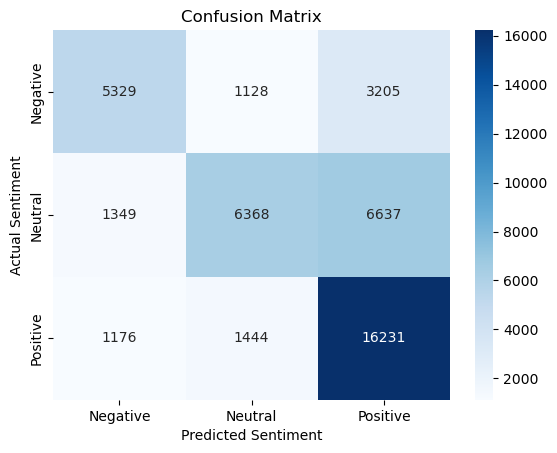

In [32]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.title('Confusion Matrix')
plt.show()

In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [34]:
tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2
)

In [35]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [36]:
X_test_tfidf = tfidf.transform(X_test)

In [37]:
print("Training Shape:", X_train_tfidf.shape)
print("Testing Shape:", X_test_tfidf.shape)

Training Shape: (171466, 30000)
Testing Shape: (42867, 30000)


In [38]:
print(tfidf.get_feature_names_out()[:20])

['aaa' 'aab' 'aadhaar' 'aadhar' 'aadhar card' 'aadmi' 'aadmi party' 'aage'
 'aah' 'aai' 'aaj' 'aaj modi' 'aaj tak' 'aajtak' 'aalo' 'aalo arunachal'
 'aam' 'aam aadmi' 'aane' 'aap']


In [39]:
print(X_train_tfidf[0].toarray())

[[0. 0. 0. ... 0. 0. 0.]]


In [40]:
from sklearn.naive_bayes import MultinomialNB

tfidf_nb_model = MultinomialNB()

tfidf_nb_model.fit(X_train_tfidf, y_train)

y_pred_tfidf_nb = tfidf_nb_model.predict(X_test_tfidf)

In [41]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_tfidf_nb))

print(classification_report(
    y_test,
    y_pred_tfidf_nb,
    target_names=['Negative', 'Neutral', 'Positive']
))

Accuracy: 0.6717055077332214
              precision    recall  f1-score   support

    Negative       0.76      0.47      0.58      9662
     Neutral       0.68      0.58      0.63     14354
    Positive       0.65      0.85      0.73     18851

    accuracy                           0.67     42867
   macro avg       0.70      0.63      0.65     42867
weighted avg       0.68      0.67      0.66     42867



In [42]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
lr_model.fit(X_train_tfidf, y_train)
y_pred_lr = lr_model.predict(X_test_tfidf)

In [43]:
from sklearn.metrics import accuracy_score, classification_report

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=['Negative', 'Neutral', 'Positive']
))

Logistic Regression Accuracy: 0.7992628362143374
              precision    recall  f1-score   support

    Negative       0.79      0.66      0.72      9662
     Neutral       0.75      0.84      0.80     14354
    Positive       0.84      0.84      0.84     18851

    accuracy                           0.80     42867
   macro avg       0.80      0.78      0.79     42867
weighted avg       0.80      0.80      0.80     42867



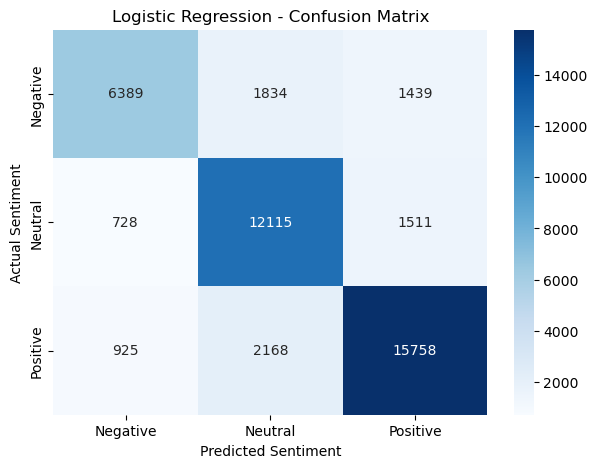

In [44]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.title('Logistic Regression - Confusion Matrix')

plt.show()

In [45]:
from sklearn.svm import LinearSVC
svm_model = LinearSVC(
    C=1.0,
    random_state=42,
    max_iter=2000
)
svm_model.fit(X_train_tfidf, y_train)
y_pred_svm = svm_model.predict(X_test_tfidf)

print(y_pred_svm[:20])

[1 1 2 1 2 2 2 1 0 1 1 0 1 0 2 1 2 2 2 1]


In [46]:
from sklearn.metrics import accuracy_score, classification_report

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

print(classification_report(
    y_test,
    y_pred_svm,
    target_names=['Negative', 'Neutral', 'Positive']
))

SVM Accuracy: 0.7902349126367603
              precision    recall  f1-score   support

    Negative       0.77      0.69      0.73      9662
     Neutral       0.75      0.82      0.78     14354
    Positive       0.84      0.82      0.83     18851

    accuracy                           0.79     42867
   macro avg       0.78      0.78      0.78     42867
weighted avg       0.79      0.79      0.79     42867



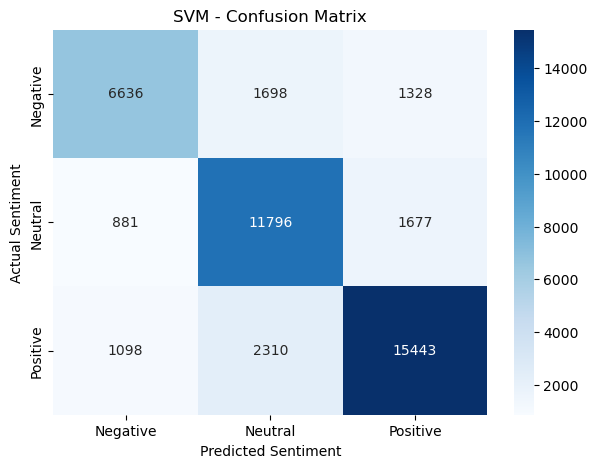

In [47]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.title('SVM - Confusion Matrix')

plt.show()

In [48]:
bow_nb_accuracy = accuracy_score(y_test, y_pred)

tfidf_nb_accuracy = accuracy_score(y_test, y_pred_tfidf_nb)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

svm_accuracy = accuracy_score(y_test, y_pred_svm)

comparison = pd.DataFrame({
    'Model': [
        'CountVectorizer + Naive Bayes',
        'TF-IDF + Naive Bayes',
        'TF-IDF + Logistic Regression',
        'TF-IDF + Linear SVM'
    ],
    'Accuracy': [
        bow_nb_accuracy,
        tfidf_nb_accuracy,
        lr_accuracy,
        svm_accuracy
    ]
})

comparison['Accuracy (%)'] = comparison['Accuracy'] * 100

comparison = comparison.sort_values(
    by='Accuracy (%)',
    ascending=False
)

print(comparison)

                           Model  Accuracy  Accuracy (%)
2   TF-IDF + Logistic Regression  0.799263     79.926284
3            TF-IDF + Linear SVM  0.790235     79.023491
1           TF-IDF + Naive Bayes  0.671706     67.170551
0  CountVectorizer + Naive Bayes  0.651503     65.150349


In [49]:
def predict_sentiment(review):

    # Clean the input text
    cleaned_review = clean_text(review)

    # Convert text into TF-IDF features
    review_tfidf = tfidf.transform([cleaned_review])

    # Predict sentiment
    prediction = lr_model.predict(review_tfidf)[0]

    # Convert numerical labels into sentiment names
    sentiment_mapping = {
        0: 'Negative',
        1: 'Neutral',
        2: 'Positive'
    }

    return sentiment_mapping[prediction]

In [50]:
review = "The product quality is excellent and delivery was fast"

result = predict_sentiment(review)

print("Customer Review:", review)
print("Predicted Sentiment:", result)

Customer Review: The product quality is excellent and delivery was fast
Predicted Sentiment: Positive


In [56]:
print(predict_sentiment("This product is very bad"))
print(predict_sentiment("The product is okay"))
print(predict_sentiment("I really love this product"))

Negative
Positive
Positive
